In [1]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


In [2]:
#np.random.seed(404)
np.set_printoptions(precision=2, suppress=True)

In [27]:
# Read data
data = pd.read_excel('Modelling_Data_Phase_3.xlsx', sheet_name ='Seed', index_col=False) #change the sheet name according to the tabs to run the various cycles in the current Phase
data=data.drop(['SCO2','SCH4','S'],axis=1)

property_interest='STY'

X=data[['Zr ', 'Cu ', 'Co ', 'Fe','T','H2:CO','GHSV']]
Y=data[property_interest].values.reshape(-1,1)

In [28]:
# 조건 만족하는 인덱스만 추출
valid_idx = np.where(Y < 400)[0]
# 이 중 랜덤 3개 선택
init_idx = np.random.choice(valid_idx, 3, replace=False)


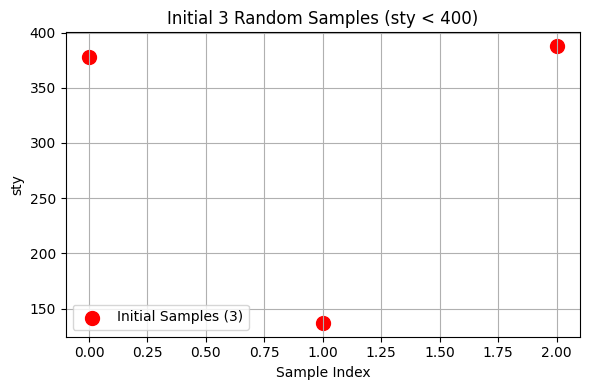

In [30]:
import matplotlib.pyplot as plt

# 선택된 3개 초기 샘플만 표시
X_init = X_scaled[init_idx]
y_init = y_scaler.inverse_transform(y_train.reshape(-1, 1))  # 다시 원래 단위로

plt.figure(figsize=(6, 4))
plt.scatter(np.arange(len(y_init)), y_init, color='red', s=100, label='Initial Samples (3)')
plt.title('Initial 3 Random Samples (sty < 400)')
plt.ylabel('sty')
plt.xlabel('Sample Index')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [31]:
from sklearn.preprocessing import MinMaxScaler
mm = MinMaxScaler(feature_range=(0,1))
mm.fit(np.array(X)[:,4:])

def scalex(x):
    x = np.array(x)
    x[:,4:] = mm.transform(x[:,4:])
    return x

In [32]:
from sklearn.preprocessing import StandardScaler

stc = StandardScaler()
stc.fit(np.array(Y))

def scaley(y):
    y_scaled = stc.transform(np.array(y))
    return y_scaled

def scaley_inv(y_scaled):
    y = stc.inverse_transform(np.array(y_scaled))
    return y

Y=scaley(Y)

In [33]:
!pip install gpflow
import gpflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 392.9/392.9 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 111.0/111.0 kB 10.8 MB/s eta 0:00:00


In [34]:
import gpflow
from gpflow.kernels import SquaredExponential,White
from gpflow.optimizers import Scipy

def gpregression(Xtrain, Ytrain):
    kernel = SquaredExponential(lengthscales=[1.0]*7) + White(variance=1e-5)

    gp=gpflow.models.GPR((Xtrain, Ytrain), kernel=kernel)

    opt = Scipy()
    opt_logs = opt.minimize(gp.training_loss, gp.trainable_variables, options={'disp':True})

    print(f"Optimized Lengthscales: {gp.kernel.kernels[0].lengthscales.numpy()}")
    print(f"Optimized Noise Variance : {gp.kernel.kernels[1].variance.numpy()}")

    return gp

<ipython-input-36-bea4784c4390>:29: UserWarning: Glyph 45936 (\N{HANGUL SYLLABLE DE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
<ipython-input-36-bea4784c4390>:29: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
<ipython-input-36-bea4784c4390>:29: UserWarning: Glyph 53552 (\N{HANGUL SYLLABLE TEO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
<ipython-input-36-bea4784c4390>:29: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
<ipython-input-36-bea4784c4390>:29: UserWarning: Glyph 48376 (\N{HANGUL SYLLABLE BON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
<ipython-input-36-bea4784c4390>:29: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
<ipython-input-36-bea4784c4390>:29: UserWarning: Glyph 45937 (\N{HANGUL SYLLABLE DEG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
<ipython-

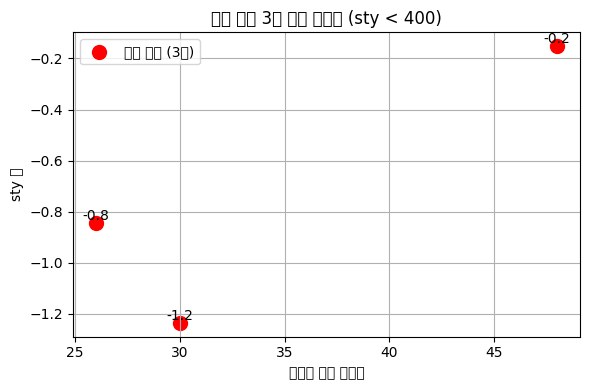

In [36]:
import matplotlib.pyplot as plt

# ─────────────────────────────────────────────────────────
# 이미 계산된 init_idx, y_raw 변수를 사용합니다.
# init_idx : 조건(sty<400) 만족한 데이터에서 랜덤 추출된 3개의 인덱스
# y_raw    : 전체 데이터의 원본 sty 값 (shape = (98,1) 또는 (98,))
# ─────────────────────────────────────────────────────────

# 1) init_idx 배열을 1D 정수 리스트로 변환
indices = init_idx.tolist()  # 예: [5, 23, 37]

# 2) 원본 sty 값 추출
#    y_raw 이 (n,1) 형태라면 flatten() 또는 reshape(-1,) 해주세요.
y_init_raw = np.array(Y).flatten()[indices]

# 3) 그래프 그리기
plt.figure(figsize=(6, 4))
plt.scatter(indices, y_init_raw, color='red', s=100, label='초기 샘플 (3개)')

# 각 점 위에 실제 값 표시
for idx, val in zip(indices, y_init_raw):
    plt.text(idx, val, f"{val:.1f}", ha='center', va='bottom')

plt.title('초기 랜덤 3개 샘플 시각화 (sty < 400)')
plt.xlabel('데이터 원본 인덱스')
plt.ylabel('sty 값')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [54]:
mean_y, var_y = gp.predict_y(X_tf)
std_y = np.sqrt(var_y.numpy().flatten())


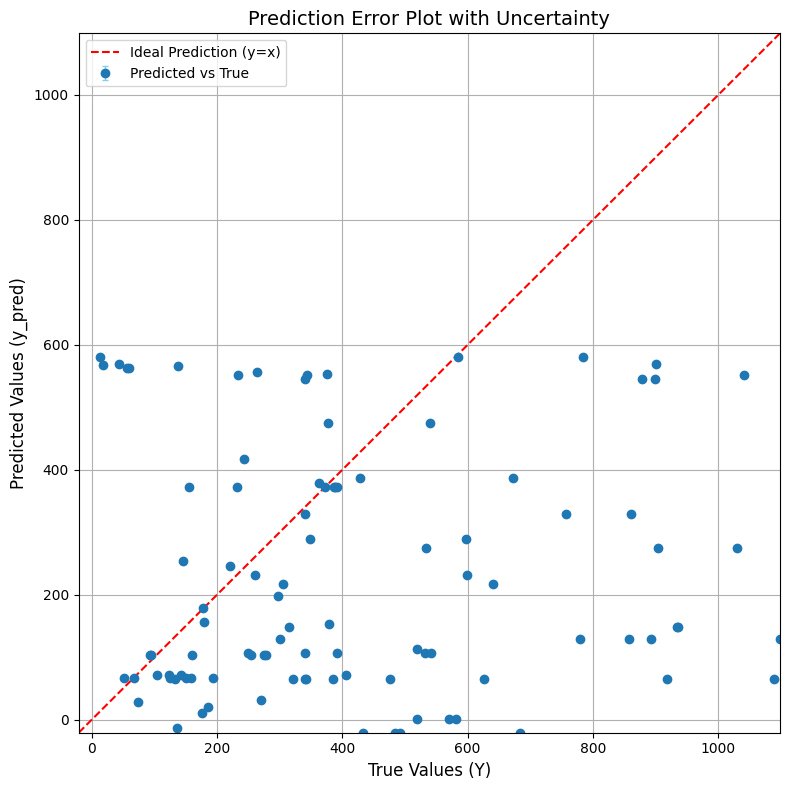

In [55]:
import matplotlib.pyplot as plt
import numpy as np

# ────────────────────────────────────────────────────────────
# 전제: 아래 변수들이 이미 준비되어 있어야 합니다.
#   y_true_actual  : 실제 sty 값, shape=(98,)
#   y_pred_actual  : 예측된 평균값, shape=(98,)
#   std_f          : 예측된 표준편차(σ), shape=(98,)
# ────────────────────────────────────────────────────────────

# 1) 에러바(errorbar) 플롯
plt.figure(figsize=(8, 8))
plt.errorbar(
    y_true_actual,             # x축: True Values
    y_pred_actual,             # y축: Predicted Values
    yerr=2*std_f,              # ±2σ (confidence interval)
    fmt='o',                   # 점 모양
    ecolor='skyblue',          # 에러바 색
    elinewidth=1,              # 에러바 선 굵기
    capsize=2,                 # 에러바 끝 캡 모양
    label='Predicted vs True'
)

# 2) Ideal line (y = x)
min_val = min(y_true_actual.min(), y_pred_actual.min()) - 0.1
max_val = max(y_true_actual.max(), y_pred_actual.max()) + 0.1
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    linewidth=1.5,
    label='Ideal Prediction (y=x)'
)

# 3) 꾸미기
plt.title('Prediction Error Plot with Uncertainty', fontsize=14)
plt.xlabel('True Values (Y)', fontsize=12)
plt.ylabel('Predicted Values (y_pred)', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.tight_layout()
plt.show()


Optimized Lengthscales: [6927.12 8080.46    0.38  441.34 2453.51 1307.77 2444.54]
Optimized Noise Variance : 3.125531921212183e-24


<ipython-input-40-2f04274f4f1e>:54: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
<ipython-input-40-2f04274f4f1e>:54: UserWarning: Glyph 49845 (\N{HANGUL SYLLABLE SEUB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
<ipython-input-40-2f04274f4f1e>:54: UserWarning: Glyph 50630 (\N{HANGUL SYLLABLE EOBS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
<ipython-input-40-2f04274f4f1e>:54: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
<ipython-input-40-2f04274f4f1e>:54: UserWarning: Glyph 49884 (\N{HANGUL SYLLABLE SI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
<ipython-input-40-2f04274f4f1e>:54: UserWarning: Glyph 44033 (\N{HANGUL SYLLABLE GAG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
<ipython-input-40-2f04274f4f1e>:54: UserWarning: Glyph 54868 (\N{HANGUL SYLLABLE HWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
<ipytho

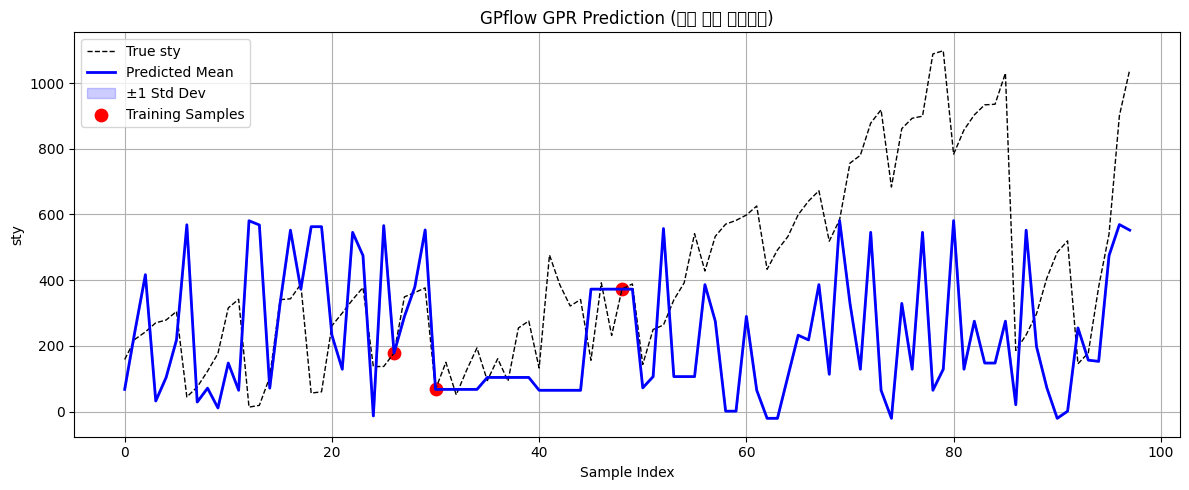

In [40]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Assuming gpregression is defined in a previous cell or imported
# and X_scaled, y_scaled, y_scaler, init_idx are available

# Initialize and train the GPR model
gp = gpregression(X_scaled[init_idx], y_scaled[init_idx])  # Using initial samples for training

# ────────────────────────────────────────────────────────────────
# 전제: 아래 변수들이 이미 정의되어 있어야 합니다.
#   gp             : gpregression(...)으로 학습된 GPflow GPR 모델
#   X_scaled       : 전체 98개 X (MinMax 스케일링된 numpy array)
#   y_scaled       : 전체 98개 y (Standard 스케일링된 numpy array, shape=(98,1))
#   y_scaler       : StandardScaler() (fit은 전체 y_raw로 이미 완료된 상태)
#   init_idx       : 초기 3개 샘플의 원본 인덱스 리스트
# ────────────────────────────────────────────────────────────────

# 1) 전체 데이터에 대한 예측
X_tf = tf.convert_to_tensor(X_scaled, dtype=gpflow.default_float())
mean_f, var_f = gp.predict_f(X_tf)           # latent mean & variance
mean_f = mean_f.numpy().flatten()             # (98,)
std_f  = np.sqrt(var_f.numpy().flatten())     # (98,)

# 2) 원단위로 복원
y_pred_actual = y_scaler.inverse_transform(mean_f.reshape(-1,1)).flatten()  # 예측치
y_true_actual = y_scaler.inverse_transform(y_scaled).flatten()              # 실제값

# 3) 시각화
plt.figure(figsize=(12,5))

# (a) 실제값
plt.plot(y_true_actual, 'k--', label='True sty', linewidth=1)

# (b) 예측 평균
plt.plot(y_pred_actual, 'b-', label='Predicted Mean', linewidth=2)

# (c) 신뢰구간 ±1 std
lower = y_pred_actual - std_f
upper = y_pred_actual + std_f
plt.fill_between(np.arange(len(y_pred_actual)), lower, upper,
                 color='blue', alpha=0.2, label='±1 Std Dev')

# (d) 학습에 쓰인 3개 샘플 강조
plt.scatter(init_idx, y_true_actual[init_idx],
            color='red', s=80, label='Training Samples')

plt.title("GPflow GPR Prediction (학습 없이 시각화만)")
plt.xlabel("Sample Index")
plt.ylabel("sty")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [57]:
# ─────────────────────────────────────────────────────────────────────────────
# STEP: Acquisition → 다음 샘플 한 점씩 선택
# ─────────────────────────────────────────────────────────────────────────────
import numpy as np
import tensorflow as tf
import gpflow
from scipy.stats import norm

# 1) 후보 풀(pool) 인덱스 정의
all_idx = np.arange(X_scaled.shape[0])
pool_idx = np.setdiff1d(all_idx, init_idx)      # init_idx: 이미 학습에 쓴 3개

# 2) GPflow predict_f → latent mean & variance
X_pool_tf = tf.convert_to_tensor(X_scaled[pool_idx], dtype=gpflow.default_float())
mean_f, var_f = gp.predict_f(X_pool_tf)
mean_f = mean_f.numpy().flatten()               # (95,)
std_f  = np.sqrt(var_f.numpy().flatten())       # (95,)

# 3) 실제 단위(sty)로 변환 → EI/PI 계산에 사용
mean_actual = y_scaler.inverse_transform(mean_f.reshape(-1,1)).flatten()
y_train_actual = y_scaler.inverse_transform(y_scaled[init_idx]).flatten()
best_y = y_train_actual.max()                   # 현재까지 관측된 최대값

# 4) Random
rand_score = np.random.rand(len(pool_idx))

# 5) EI (Expected Improvement)
z = (mean_actual - best_y) / (std_f + 1e-9)
ei_score = (mean_actual - best_y) * norm.cdf(z) + std_f * norm.pdf(z)

# 6) PI / MLI (Probability of Improvement)
pi_score = norm.cdf(z)

# 7) MU (Maximum Uncertainty)
mu_score = std_f

# 8) 각 전략이 고른 다음 인덱스
next_rand = pool_idx[np.argmax(rand_score)]
next_ei   = pool_idx[np.argmax(ei_score)]
next_pi   = pool_idx[np.argmax(pi_score)]
next_mu   = pool_idx[np.argmax(mu_score)]

print(f"Next(Random) idx = {next_rand}")
print(f"Next(EI)     idx = {next_ei}")
print(f"Next(PI)     idx = {next_pi}")
print(f"Next(MU)     idx = {next_mu}")


Next(Random) idx = 29
Next(EI)     idx = 80
Next(PI)     idx = 2
Next(MU)     idx = 92


In [58]:
# ─────────────────────────────────────────────────────────────────────────────
# ▶ STEP: Active Learning 비교 (Random, MEI(EI), MLI(PI), MU)
#    각 전략별로 “sty ≥ 1100”이 나올 때까지 반복하고
#    iteration별 최대 관측값을 기록 → 한 그래프로 비교
# ─────────────────────────────────────────────────────────────────────────────

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from scipy.stats import norm

# 1) 전략 리스트 및 결과 저장용
methods = ['Random', 'MEI', 'MLI', 'MU']
histories = {}

# 2) 반복 기준
THRESHOLD = 1100

for method in methods:
    # • 초기 학습 인덱스 복사
    current_idx = init_idx.copy()
    # • 관측된 원단위 sty 값
    y_obs = y_true_actual.copy()  # shape=(98,)
    # • 현재까지 관측된 최대값
    max_seen = y_obs[current_idx].max()
    history = [max_seen]

    # • 후보 풀 인덱스
    pool_idx = np.setdiff1d(np.arange(len(y_obs)), current_idx)

    # 3) 반복 탐색
    while max_seen < THRESHOLD:
        # 3.1) GP 모델 재학습
        gp = gpregression(
            X_scaled[current_idx],
            y_scaled[current_idx]
        )
        # 3.2) 후보 풀에 대한 예측 (latent mean & var)
        X_pool_tf = tf.convert_to_tensor(
            X_scaled[pool_idx],
            dtype=gpflow.default_float()
        )
        mean_f, var_f = gp.predict_f(X_pool_tf)
        mean_f = mean_f.numpy().flatten()
        std_f  = np.sqrt(var_f.numpy().flatten())

        # 3.3) acquisition 점수 계산
        if method == 'Random':
            scores = np.random.rand(len(pool_idx))
        else:
            # 실제 단위 sty로 변환
            mean_actual = y_scaler.inverse_transform(
                mean_f.reshape(-1,1)
            ).flatten()
            best_y = max_seen

            # z-값
            z = (mean_actual - best_y) / (std_f + 1e-9)

            if method == 'MEI':       # = EI
                scores = (mean_actual - best_y) * norm.cdf(z) \
                         + std_f * norm.pdf(z)
            elif method == 'MLI':     # = PI
                scores = norm.cdf(z)
            elif method == 'MU':
                scores = std_f

        # 3.4) 다음 샘플 선택
        next_idx = pool_idx[np.argmax(scores)]

        # 3.5) 관측값 업데이트
        current_idx = np.append(current_idx, next_idx)
        pool_idx = pool_idx[pool_idx != next_idx]
        max_seen = max(max_seen, y_obs[next_idx])
        history.append(max_seen)

    histories[method] = history

# 4) 결과 시각화
plt.figure(figsize=(8, 6))
for method, hist in histories.items():
    plt.plot(hist, marker='o', label=method)

plt.axhline(THRESHOLD, color='red', linestyle='--', label=f'Threshold = {THRESHOLD}')
plt.title('Active Learning: Iteration vs. Max Observed sty')
plt.xlabel('Iteration')
plt.ylabel('Max Observed sty')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Optimized Lengthscales: [6927.12 8080.46    0.38  441.34 2453.51 1307.77 2444.54]
Optimized Noise Variance : 3.125531921212183e-24
Optimized Lengthscales: [15144.91 16213.74  7989.3   6512.55     0.3      0.73  7980.86]
Optimized Noise Variance : 1.4040770177732937e-28
Optimized Lengthscales: [19426.69 22501.54     0.39 17901.53     0.96 15684.09     0.83]
Optimized Noise Variance : 4.559472598582569e-36
Optimized Lengthscales: [6554.73 7432.54    0.77    0.63 1389.91 6049.25    0.42]
Optimized Noise Variance : 9.95289243954682e-11
Optimized Lengthscales: [11708.77 14410.78     1.44     0.58  3117.02 14415.19     0.42]
Optimized Noise Variance : 3.689670183875008e-20
Optimized Lengthscales: [41176.16 51339.8      1.17     1.2  12494.79 77863.54     0.76]
Optimized Noise Variance : 0.0
Optimized Lengthscales: [18101.66 21463.74     0.94     0.83     0.83 39938.       0.77]
Optimized Noise Variance : 1.7189363980872186e-236
Optimized Lengthscales: [   0.45 2321.04 4968.78    0.8     0.08

ValueError: attempt to get argmax of an empty sequence

Optimized Lengthscales: [6927.12 8080.46    0.38  441.34 2453.51 1307.77 2444.54]
Optimized Noise Variance : 3.125531921212183e-24
Optimized Lengthscales: [31514.96 37788.95 35841.73 21849.21  9724.16     1.1  28599.95]
Optimized Noise Variance : 0.0
Optimized Lengthscales: [3655.47 3706.01 5013.47 5622.33    0.28    1.54    1.76]
Optimized Noise Variance : 4.336701040194929e-19
Optimized Lengthscales: [    3.48 12188.3  10822.94     3.01     0.83  5693.96     1.91]
Optimized Noise Variance : 5.4453371192152143e-126
Optimized Lengthscales: [     8.6  245020.92 240273.88     10.        1.84 252556.42      3.67]
Optimized Noise Variance : 0.0
Optimized Lengthscales: [1818.79 1916.3  2502.6     1.52    0.24    1.15 4205.66]
Optimized Noise Variance : 6.056734551566139e-06
Optimized Lengthscales: [15881.23 17927.2   7642.53     0.29     0.43 13694.01     1.23]
Optimized Noise Variance : 2.0376089459404156e-08
Optimized Lengthscales: [ 8637.65 10470.02     0.32     0.54     0.33 12854.2    

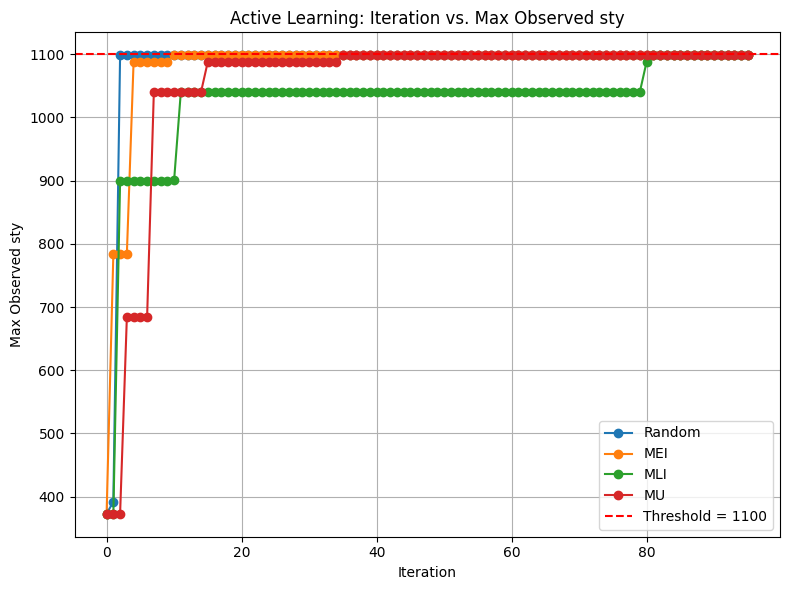

In [59]:
# ─────────────────────────────────────────────────────────────────────────────
# ▶ STEP: Active Learning 비교 (Random, MEI(EI), MLI(PI), MU)
#    각 전략별로 “sty ≥ 1100”이 나올 때까지 반복하고
#    iteration별 최대 관측값을 기록 → 한 그래프로 비교
# ─────────────────────────────────────────────────────────────────────────────

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from scipy.stats import norm

# 1) 전략 리스트 및 결과 저장용
methods = ['Random', 'MEI', 'MLI', 'MU']
histories = {}

# 2) 반복 기준
THRESHOLD = 1100

for method in methods:
    # • 초기 학습 인덱스 복사
    current_idx = init_idx.copy()
    # • 관측된 원단위 sty 값
    y_obs = y_true_actual.copy()  # shape=(98,)
    # • 현재까지 관측된 최대값
    max_seen = y_obs[current_idx].max()
    history = [max_seen]

    # • 후보 풀 인덱스
    pool_idx = np.setdiff1d(np.arange(len(y_obs)), current_idx)

    # 3) 반복 탐색
    while max_seen < THRESHOLD and len(pool_idx) > 0:  # Add condition to check if pool_idx is empty
        # 3.1) GP 모델 재학습
        gp = gpregression(
            X_scaled[current_idx],
            y_scaled[current_idx]
        )
        # 3.2) 후보 풀에 대한 예측 (latent mean & var)
        X_pool_tf = tf.convert_to_tensor(
            X_scaled[pool_idx],
            dtype=gpflow.default_float()
        )
        mean_f, var_f = gp.predict_f(X_pool_tf)
        mean_f = mean_f.numpy().flatten()
        std_f  = np.sqrt(var_f.numpy().flatten())

        # 3.3) acquisition 점수 계산
        if method == 'Random':
            scores = np.random.rand(len(pool_idx))
        else:
            # 실제 단위 sty로 변환
            mean_actual = y_scaler.inverse_transform(
                mean_f.reshape(-1,1)
            ).flatten()
            best_y = max_seen

            # z-값
            z = (mean_actual - best_y) / (std_f + 1e-9)

            if method == 'MEI':       # = EI
                scores = (mean_actual - best_y) * norm.cdf(z) \
                         + std_f * norm.pdf(z)
            elif method == 'MLI':     # = PI
                scores = norm.cdf(z)
            elif method == 'MU':
                scores = std_f

        # 3.4) 다음 샘플 선택
        next_idx = pool_idx[np.argmax(scores)]

        # 3.5) 관측값 업데이트
        current_idx = np.append(current_idx, next_idx)
        pool_idx = pool_idx[pool_idx != next_idx]
        max_seen = max(max_seen, y_obs[next_idx])
        history.append(max_seen)

    histories[method] = history

# 4) 결과 시각화
plt.figure(figsize=(8, 6))
for method, hist in histories.items():
    plt.plot(hist, marker='o', label=method)

plt.axhline(THRESHOLD, color='red', linestyle='--', label=f'Threshold = {THRESHOLD}')
plt.title('Active Learning: Iteration vs. Max Observed sty')
plt.xlabel('Iteration')
plt.ylabel('Max Observed sty')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

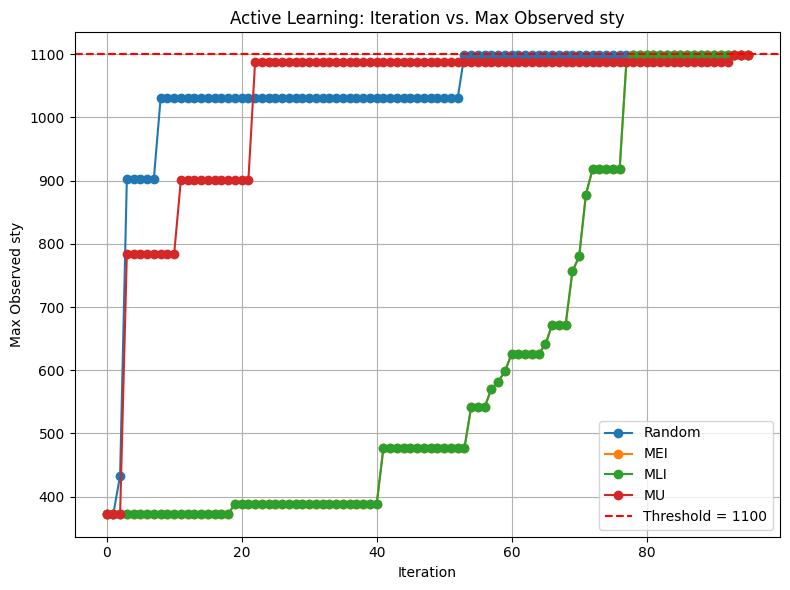

In [62]:
# ─────────────────────────────────────────────────────────────────────────────
# ▶ STEP: Active Learning 비교 (Random, MEI, MLI, MU) — 하이퍼파라미터 동결 버전
#    • 초기 3개 샘플로만 한 번 하이퍼파라미터 최적화
#    • 이후 반복에서는 최적화 건너뛰고 동결된 하이퍼파라미터로 예측·획득함수 계산
#    • sty ≥ 1100 이 되는 시점까지 각 전략별로 몇 번만에 찾는지 기록
# ─────────────────────────────────────────────────────────────────────────────

import numpy as np
import tensorflow as tf
import gpflow
from gpflow.kernels import SquaredExponential, White
from gpflow.optimizers import Scipy
from scipy.stats import norm
import matplotlib.pyplot as plt

# 0) GPflow 기본 실수형 설정
gpflow.config.set_default_float(tf.float64)

# 1) 초기 3개 샘플로 하이퍼파라미터 한 번만 최적화
X_init_tf = tf.convert_to_tensor(X_scaled[init_idx], dtype=gpflow.default_float())
y_init_tf = tf.convert_to_tensor(y_scaled[init_idx], dtype=gpflow.default_float())

kernel0 = SquaredExponential(lengthscales=[1.0]*7) + White(variance=1e-5)
gp0 = gpflow.models.GPR(data=(X_init_tf, y_init_tf), kernel=kernel0)
opt = Scipy()
opt.minimize(gp0.training_loss_closure(),
             gp0.trainable_variables,
             options={'disp': False, 'maxiter': 100})

# 최적화된 하이퍼파라미터 저장
best_ls  = gp0.kernel.kernels[0].lengthscales.numpy()
best_var = gp0.kernel.kernels[1].variance.numpy()

# 2) Active Learning 루프
methods    = ['Random', 'MEI', 'MLI', 'MU']
histories  = {}
THRESHOLD  = 1100
y_obs      = y_scaler.inverse_transform(y_scaled).flatten()
all_idx    = np.arange(len(y_obs))

for method in methods:
    current_idx = init_idx.copy()
    pool_idx    = np.setdiff1d(all_idx, current_idx)
    max_seen    = y_obs[current_idx].max()
    history     = [max_seen]

    while max_seen < THRESHOLD and len(pool_idx) > 0:
        # (a) 모델 정의 — 하이퍼파라미터는 동결
        X_train_tf = tf.convert_to_tensor(
            X_scaled[current_idx], dtype=gpflow.default_float()
        )
        y_train_tf = tf.convert_to_tensor(
            y_scaled[current_idx], dtype=gpflow.default_float()
        )
        kernel     = SquaredExponential(lengthscales=best_ls) + White(variance=best_var)
        gp         = gpflow.models.GPR(data=(X_train_tf, y_train_tf), kernel=kernel)

        # (b) 후보 풀 예측
        X_pool_tf  = tf.convert_to_tensor(
            X_scaled[pool_idx], dtype=gpflow.default_float()
        )
        mean_f, var_f = gp.predict_f(X_pool_tf)
        mean_f = mean_f.numpy().flatten()
        std_f  = np.sqrt(var_f.numpy().flatten())

        # (c) 획득함수 계산
        if method == 'Random':
            scores = np.random.rand(len(pool_idx))
        else:
            mean_actual = y_scaler.inverse_transform(
                mean_f.reshape(-1,1)
            ).flatten()
            best_y = max_seen
            z      = (mean_actual - best_y) / (std_f + 1e-9)
            if method == 'MEI':    # Expected Improvement
                scores = (mean_actual - best_y) * norm.cdf(z) + std_f * norm.pdf(z)
            elif method == 'MLI':  # Probability of Improvement
                scores = norm.cdf(z)
            else:                  # MU = Maximum Uncertainty
                scores = std_f

        # (d) 다음 샘플 선택 및 업데이트
        next_idx     = pool_idx[np.argmax(scores)]
        current_idx  = np.append(current_idx, next_idx)
        pool_idx     = pool_idx[pool_idx != next_idx]
        max_seen     = max(max_seen, y_obs[next_idx])
        history.append(max_seen)

    histories[method] = history

# 3) 결과 비교 그래프
plt.figure(figsize=(8, 6))
for method, hist in histories.items():
    plt.plot(hist, marker='o', label=method)
plt.axhline(THRESHOLD, color='red', linestyle='--', label=f'Threshold = {THRESHOLD}')
plt.title('Active Learning: Iteration vs. Max Observed sty')
plt.xlabel('Iteration')
plt.ylabel('Max Observed sty')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [63]:
print(histories.keys())
print("MEI 히스토리:", histories.get('MEI'))


dict_keys(['Random', 'MEI', 'MLI', 'MU'])
MEI 히스토리: [np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(372.7199124451185), np.float64(387.62267229689274), np.float64(387.62267229689274), np.float64(387.62267229689274), np.float64(387.62267229689274), np.float64(387.62267229689274), np.float64(387.62267229689274), np.float64(387.62267229689274), np.float64(387.62267229689274), np.float64(387.62267229689274), np.float64(387.62267229689274), np.float64(387.62267229689274), np.flo